# Lab 11-10 · Sampling, Aliasing and Reconstruction

Companion to [chapter 11-10](../../chapters/11-10-sampling-aliasing-reconstruction.md). Four parts: folding, reconstruction, noise and filters, and a biopotential converter's anti-aliasing chain. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
rng = np.random.default_rng(11)

## Part 1 — Folding

Sample tones at 48 kHz and find the FFT peak; then sample a chirp from 0 to 100 kHz and track its apparent frequency.

  30.0 kHz appears at 18.00 kHz
  50.0 kHz appears at 2.00 kHz
  96.5 kHz appears at 0.50 kHz


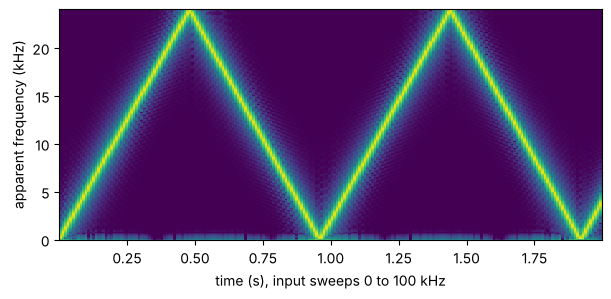

In [2]:
fs = 48e3
N = 48000
n = np.arange(N)
for f0 in (30e3, 50e3, 96.5e3):
    X = np.abs(np.fft.rfft(np.cos(2 * np.pi * f0 * n / fs)))
    print(f"{f0 / 1e3:6.1f} kHz appears at {np.argmax(X) * fs / N / 1e3:.2f} kHz")

t = np.arange(int(2 * fs)) / fs
chirp = signal.chirp(t, f0=0, t1=t[-1], f1=100e3)
f_spec, t_spec, S = signal.spectrogram(chirp, fs=fs, nperseg=512)
fig, ax = plt.subplots(figsize=(7, 3))
ax.pcolormesh(t_spec, f_spec / 1e3, 10 * np.log10(S + 1e-12), shading="auto")
ax.set_xlabel("time (s), input sweeps 0 to 100 kHz"); ax.set_ylabel("apparent frequency (kHz)")
plt.show()

## Part 2 — Reconstruction

Sinc interpolation of a band-limited signal (sum of tones below 10 kHz) sampled at 48 kHz, evaluated between the samples and compared with the true signal.

In [3]:
fs = 48e3; T = 1 / fs
tones = [(1.3e3, 1.0, 0.2), (4.7e3, 0.5, 1.1), (9.1e3, 0.3, 2.0)]
x = lambda tt: sum(a * np.cos(2 * np.pi * f * tt + p) for f, a, p in tones)
nn = np.arange(0, 960)
xs = x(nn * T)
tq = np.linspace(400 * T, 560 * T, 801)
xr = np.array([np.sum(xs * np.sinc((tt - nn * T) / T)) for tt in tq])
print("largest sinc-interpolation error in the middle of the record:", np.max(np.abs(xr - x(tq))))
tq_edge = np.linspace(2 * T, 20 * T, 200)
xr_edge = np.array([np.sum(xs * np.sinc((tt - nn * T) / T)) for tt in tq_edge])
print("largest error near the start of the record:", np.max(np.abs(xr_edge - x(tq_edge))))

largest sinc-interpolation error in the middle of the record: 0.00092464739197895
largest error near the start of the record: 0.07699622260482103


Now a zero-order hold: the staircase of a 20 kHz tone at 48 kHz on a grid 1024 times finer, and its spectrum.

In [4]:
over = 1024
xs = np.cos(2 * np.pi * 20e3 * np.arange(1200) / 48e3)
st = np.repeat(xs, over)
X = np.fft.rfft(st) / (len(st) / 2)
df = 48e3 * over / len(st)
for f in (20e3, 28e3, 68e3, 76e3):
    print(f"{f / 1e3:5.0f} kHz: {20 * np.log10(abs(X[int(round(f / df))])):7.2f} dB  (sinc: {20 * np.log10(abs(np.sinc(f / 48e3))):7.2f} dB)")

   20 kHz:   -2.64 dB  (sinc:   -2.64 dB)
   28 kHz:   -5.56 dB  (sinc:   -5.56 dB)
   68 kHz:  -13.27 dB  (sinc:  -13.27 dB)
   76 kHz:  -14.24 dB  (sinc:  -14.24 dB)


## Part 3 — Noise folding and filter orders

White noise band-limited to 1 MHz, sampled at 48 kHz with and without an ideal 24 kHz filter.

In [5]:
M = 42; fsim = 48e3 * M; Nn = 2 ** 21
w = rng.normal(size=Nn)
W = np.fft.rfft(w); fr = np.fft.rfftfreq(Nn, 1 / fsim)
wide = np.fft.irfft(W * (fr <= 1e6), Nn)[::M]
filt = np.fft.irfft(W * (fr <= 24e3), Nn)[::M]
print(f"in-band noise increase without the filter: {10 * np.log10(np.var(wide) / np.var(filt)):.2f} dB"
      f"  (predicted {10 * np.log10(1e6 / 24e3):.2f} dB)")

in-band noise increase without the filter: 16.24 dB  (predicted 16.20 dB)


In [6]:
def order(A, f_alias, fc):
    return math.ceil(math.log(10 ** (A / 10) - 1) / (2 * math.log(f_alias / fc)))
print(" OSR   f_s (kHz)   Butterworth order for 90 dB at f_s - 20 kHz")
for osr in (1, 2, 4, 8, 16, 64, 128):
    fs_ = 48e3 * osr
    print(f"{osr:4d}   {fs_ / 1e3:9.0f}   {order(90, fs_ - 20e3, 20e3):3d}")

 OSR   f_s (kHz)   Butterworth order for 90 dB at f_s - 20 kHz
   1          48    31
   2          96     8
   4         192     5
   8         384     4
  16         768     3
  64        3072     3
 128        6144     2


## Part 4 — The ADS1292R chain (guided exercise)

**Predict first:** a 450 Hz and a 127.95 kHz interferer of equal amplitude both alias to 50 Hz at the 500 SPS output. Which arrives stronger, and by how much? Then run: an RC filter at 8.4 kHz (applied as its gain at the interferer frequency), sampling at 128 kHz, and a sinc³ decimator (three 256-sample boxcars, then keep every 256th sample).

In [7]:
fM, Nd = 128e3, 256
rc = lambda f: 1 / abs(1 + 1j * f / 8.4e3)
def chain(f_in, seconds=4.0):
    n = np.arange(int(fM * seconds))
    x = rc(f_in) * np.cos(2 * np.pi * f_in * n / fM)
    box = np.ones(Nd) / Nd
    y = signal.lfilter(box, 1, signal.lfilter(box, 1, signal.lfilter(box, 1, x)))[::Nd][20:]
    m = np.arange(len(y))
    c = np.linalg.lstsq(np.column_stack([np.cos(2 * np.pi * 50 * m / 500), np.sin(2 * np.pi * 50 * m / 500)]), y, rcond=None)[0]
    return 20 * np.log10(np.hypot(*c))
a450, a128 = chain(450.0), chain(127.95e3)
print(f"450 Hz interferer at the output: {a450:.1f} dB;  127.95 kHz interferer: {a128:.1f} dB;  difference {a128 - a450:.1f} dB")

450 Hz interferer at the output: -57.7 dB;  127.95 kHz interferer: -24.1 dB;  difference 33.6 dB


The decimation filter is periodic in the modulator rate, so it gives almost no protection near 128 kHz; only the RC filter (23.7 dB there) stands in the way. That is the data sheet's warning in numbers.